In [12]:
import glob
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import FormatStrFormatter
import matplotlib.ticker as mticker
import matplotlib.colors
from matplotlib import rcParams
from matplotlib import ticker

In [13]:
#Constants
mJy = 1.0e-26
dist = 1.72*3.0856e21  # Distance to the source = 2.4 kpc
h = 6.6260755e-27     # erg.seg
eV = 1.602176e-12     # 1 eV = 1.602176e-12 erg
a = 4.0*np.pi*dist**2    

In [14]:
def read_SED(filename):
    '''This function reads the frequency and fluxes of the spectrum.
    Output: nu[GHz], S[mJy]'''
    
    fname = filename
    SED = np.loadtxt(fname) # E, L_unabs, L_abs
    nu = SED[:,0]*1e-9
    S = SED[:,1]
    
    return nu, S

In [15]:
# Armo los objetos con los puntos observacionales

#ATCA_data = np.loadtxt('../data_radio_apep.dat')
#nu_ATCA, nu_ATCA_err = ATCA_data[:,0], ATCA_data[:,2]
#flux_ATCA, flux_ATCA_err = ATCA_data[:,1], ATCA_data[:,3] 

# MSX (Benaglia+2010)
msx_data = np.loadtxt('Benaglia_2010.dat')
nu_msx, nu_msx_err = msx_data[:,0], msx_data[:,1]
flux_msx, flux_msx_err = msx_data[:,2], msx_data[:,2]*0.1

# jVLA (Benaglia+2021)
jvla_data = np.loadtxt('Benaglia_2021.dat')
nu_jvla, nu_jvla_err = jvla_data[:,0], jvla_data[:,2]
flux_jvla, flux_jvla_err = 1000.*jvla_data[:,1],1000.*jvla_data[:,3]

# jVLA (Benaglia+2021)
jvla_B_data = np.loadtxt('Benaglia_2021_B.dat')
nu_jvla_B, nu_jvla_B_err = jvla_B_data[:,0], jvla_B_data[:,2]
flux_jvla_B, flux_jvla_B_err = 1000.*jvla_B_data[:,1],1000.*jvla_B_data[:,3]

# Feathered data (Moutzouri+2022)
feat_data = np.loadtxt('Moutzouri_2022.dat')
nu_feat, nu_feat_err = feat_data[:,0], feat_data[:,1]/2.
flux_feat, flux_feat_err = (feat_data[:,2]-feat_data[:,3]), 0.05*(feat_data[:,2]-feat_data[:,3])

# VdE 2022
nu_VdE = np.array([0.8875])
nu_VdE_err = np.array([0.288/2.])

HD_319881 = np.array([5.97])
HD_319881_err = 0.05*HD_319881

RCW_49_S1 = np.array([12.6])
RCW_49_S1_err = 0.05*RCW_49_S1

G1 = np.array([8.0])
G1_err = 0.05*G1

HIP_98418 = np.array([5.3])
HIP_98418_err = 0.05*HIP_98418

HIP_88652 = np.array([2.24])
HIP_88652_err = 0.05*HIP_88652

# VdE 2022 (Vela X-1)
nu_VX1 = np.array([1.3])
nu_VX1_err = np.array([0.856/2])

V_X1 = np.array([5.27])
V_X1_err = np.array([0.07])

In [16]:
# Define the names of the files with the SEDs (sync and f-f)
file_syn = '../../S_syn_RS.dat'        # synchrotron
file_ff = '../../S_ff_FS.dat'          # post shock f-f
file_ion_ff = '../../S_ionizedFS.dat' # cooled layer in FS ionized by the star f-f
file_ISM = '../../flux_ISM.dat'   # unshocked ISM ionized by the star

# Read the SEDs (format: nu [GHz], S_nu [mJy] )
#SED_syn = read_SED(file_syn)
#SED_ff = read_SED(file_ff)   
#SED_ion = read_SED(file_ion_ff) 
#SED_ISM = read_SED(file_ISM)
nu_sy, S_sy = read_SED(file_syn)
nu_ff, S_ff = read_SED(file_ff)   
nu_ion, S_ion = read_SED(file_ion_ff) 
nu_ISM, S_ISM = read_SED(file_ISM)

In [17]:
#INTERPOLATE THE SEDS AND ADD THE TOTAL:

#Smooth curves (should be evaluated in other energies...)
#cubic_interpolation_model = interp1d(Eic2, Fic2, kind = "cubic")
#Fic2 = cubic_interpolation_model(Eic2) 
#cubic_interpolation_model = interp1d(Epp2, Fpp2, kind = "cubic")
#Fpp2 = cubic_interpolation_model(Epp2) 

# creating interpolator
p1 = lambda x: np.interp(x, nu_sy, S_sy)
p2 = lambda x: np.interp(x, nu_ff, S_ff)
p3 = lambda x: np.interp(x, nu_ion, S_ion)
#p3 = lambda x: np.interp(x, nu_ISM, S_ISM)

# calculate the minimum and maximum E values
nu_min = min(min(nu_sy), min(nu_ff), min(nu_ion), min(nu_ISM) ) 
nu_max = max(max(nu_sy), max(nu_ff), max(nu_ion), max(nu_ISM) )

nu = np.geomspace(nu_min, nu_max, 400)
S_tot = [ p1(i) + p2(i) + p3(i) for i in nu]

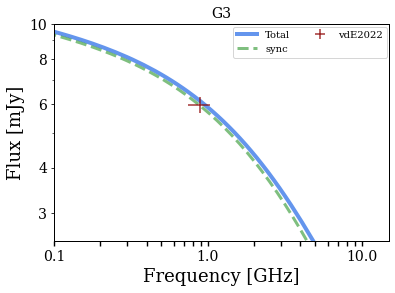

In [18]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = 1#len(Mdots)
color_vector = np.linspace(0.2,0.9,n)
colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('copper_r', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
#sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Definiciones estéticas
nice_fonts = {
        # Use LaTeX to write all text
#        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 18,
        "font.size": 14,
        "axes.linewidth":1,
        "axes.titlesize":14,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 14,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "xtick.major.size": 5,     # major tick size in points
        "xtick.minor.size": 5,       # minor tick size in points
        "xtick.major.width": 1.4,     # major tick width in points
        "xtick.minor.width": 1.4,     # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

# Set labels
#plt.setp(ax, xlabel=r"$\nu$ [GHz]")
plt.setp(ax, xlabel=r"Frequency [GHz]")
#plt.setp(ax, ylabel=r"$S_\nu$ [mJy]")
plt.setp(ax, ylabel=r"Flux [mJy]")

# Definiciones generales
#plt.xlim(1, 15)
plt.xlim(0.1,15)
#plt.ylim(100,800)
#plt.ylim(1,20)
plt.ylim(2.5,10)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(nu, S_tot, ls='-', color='cornflowerblue', linewidth=4, label='Total', zorder=1)
    plt.plot(nu_sy, S_sy, ls='--', color='green', linewidth=3,alpha=0.5, label='sync', zorder=1)
    #plt.plot(nu_ff, S_ff, ls='--', color='green', linewidth=3, alpha=0.5, label='f-f', zorder=1)
    #plt.plot(nu_ion, S_ion, ls=':', color='darkblue', linewidth=3, alpha=0.7, label='f-f IL', zorder=1)
    #plt.plot(nu_ISM, S_ISM, ls='--', color='grey', linewidth=3, alpha=0.99, label='ISM', zorder=1)

# Grafico cada set de datos y sus barras de error
# BD+43°3654
#plt.title('BD+43° 3654')
#plt.errorbar(nu_msx, flux_msx, yerr=flux_msx_err, xerr=nu_msx_err, lolims=True, ecolor='magenta', alpha=0.6, fmt='none', label='B2010',zorder=2)#, , ecolor='blue', alpha=0.8, fmt='none', label = 'Benaglia+2010')
#plt.errorbar(nu_jvla, flux_jvla, yerr=flux_jvla_err, xerr=nu_jvla_err, ecolor='k', alpha=0.4, fmt='none', label = 'B2021-A',zorder=2)
#plt.errorbar(nu_jvla_B, flux_jvla_B, yerr=flux_jvla_B_err, xerr=nu_jvla_B_err, ecolor='k', alpha=0.8, fmt='none', label = 'B2021-B',zorder=2)
#plt.errorbar(nu_feat, flux_feat, yerr=flux_feat_err, xerr=nu_feat_err, ecolor='darkred', alpha=0.9, fmt='none', label = 'M2022', zorder=2)

# HD 319881
plt.title('G3')
plt.errorbar(nu_VdE, HD_319881, yerr=HD_319881_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

# RCW 49 S1
#plt.title('RCW 49 S1')
#plt.errorbar(nu_VdE, RCW_49_S1, yerr=RCW_49_S1_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

# G1
#plt.title('G1')
#plt.errorbar(nu_VdE, G1, yerr=G1_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

# HIP 98418
#plt.title('HIP 98418')
#plt.errorbar(nu_VdE, HIP_98418, yerr=HIP_98418_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

# HIP 88652
#plt.title('HIP 88652')
#plt.errorbar(nu_VdE, HIP_88652, yerr=HIP_88652_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

# Vela X-1
#plt.title('Vela X-1 - T')
#plt.errorbar(nu_VX1, V_X1, yerr=V_X1_err, xerr=nu_VX1_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

plt.legend( bbox_to_anchor=(0.01, 0.01, 1., 1.), loc='upper right', ncol=2,prop={'size': 10},fontsize=22)
#plt.legend( bbox_to_anchor=(0.01, 0.01, 1., .102), loc='lower left', ncol=1,prop={'size': 10},fontsize=22)
ax.loglog()
#ax.xaxis.set_minor_formatter(mticker.ScalarFormatter())
#ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
ax.set_yscale('log')
#ax.set_yticks([200, 300, 400, 500, 600, 700])
#ax.set_yticks([5,10,20])
ax.set_yticks([3,4,6,8,10])
#ax.set_xticks([1,10])
ax.set_xticks([0.1,1,10])
ax.get_yaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
#cbar = fig.colorbar(sm, ticks=c, label=r"$\dot{M}$ [$10^{-5}$ M$_\odot$ yr$^{-1}$]", pad=0.02)
#cbar.ax.set_yticklabels(Mdots)  # vertically oriented colorbar

#ax.text(0.25, 0.02, r'$\eta_{\rm H}$ = 0.06',family='serif', fontsize=12)
#ax.text(0.75, 0.02, r'$L_{\rm inj,e} = 0.1 L_\perp$',family='serif', fontsize=12)
#ax.text(3, 0.02, r'$\eta_{\rm B} = 0.1$',family='serif', fontsize=12)
#ax.text(9., 0.02, r'$\alpha = 2$',family='serif', fontsize=12)
#ax.text(6.5, 0.015, r'$L_{\rm inj,e} = 0.01 L_\perp$',family='serif', fontsize=11)
#ax.text(0.22, 750., "BD+43° 3654", family='serif', fontsize=11)
#ax.text(3., 50., r'$\eta_{\rm B} = 0.1 \quad L_{\rm inj,e} = 0.01 L_\perp$',family='serif', fontsize=11)
#ax.text(0.108, 50., "HD 319881", family='serif', fontsize=11)

#plt.show()

In [20]:
fig.savefig('G3.pdf', bbox_inches='tight', pad_inches = 0)